![Banner](../../../../Images/Banner/07_remote_sensing/09_11_banner_rs_foundation_models.png)

# AlphaEarth Foundations: Precomputed Embeddings for the Whole Planet

Every notebook so far ran a model to get embeddings. Google DeepMind's AlphaEarth Foundations turns
that around: the model has already been run over the whole land surface, every year since 2017, and
the result is published as a 64-band image at 10 m, the Satellite Embedding dataset, in Earth Engine
and as free public files that need no account.
No GPU, no preprocessing, no input contract: each pixel already carries a summary of a year of
optical, radar, lidar, climate and other observations. This notebook reads it for the Iowa Corn
Belt from the public copy, looks at what the 64 dimensions show, finds fields like a chosen one, clusters the landscape
without labels, detects change between years, and compares AlphaEarth with DOFA and SSL4EO on the
same crop probe.

## Overview

### Embedding fields

AlphaEarth Foundations (Brown et al. 2025) is a model that learns an **embedding field**: a function
from a place and a time period to a vector. It was trained on more than 3 billion observations from
Sentinel-1 and 2, Landsat 8 and 9, GEDI lidar, the GLO-30 elevation model, ERA5 climate, GRACE
gravity and text descriptions, with objectives that reconstruct those sources and keep the vectors
consistent in space and time. The published product summarises each calendar year at each 10 m pixel.

| Property | Value |
|---|---|
| Earth Engine collection | `GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL` |
| Bands | `A00` to `A63`, 64 float values |
| Resolution | 10 m, in local UTM tiles |
| Time | one image per calendar year, 2017 onward |
| Length | every vector has length 1 (unit sphere) |
| Licence | CC BY 4.0 (check the dataset page) |

### What unit length means

Because every vector has length 1, the **dot product of two pixels is their cosine similarity**: 1
for identical, near 0 for unrelated. Similarity search and change detection are therefore a few lines
of arithmetic. Averaging pixels shortens the vector, so averaged embeddings are re-normalised before
comparing them.

### Strengths and limits

- **Strengths**: no model to run; the same representation everywhere; many sensors combined, so
  clouds matter less; a year of phenology in each vector.
- **Limits**: one vector per year (no within-season maps); the dimensions have no names; the product
  is computed by Google and its exact inputs cannot be audited pixel by pixel; access through Earth
  Engine; licence terms apply.

### Three ways to get the embeddings

| Source | Format | Account | Best for |
|---|---|---|---|
| Source Cooperative GeoZarr mosaic | one global Zarr array, EPSG:4326, ~10 m, chunks of 256 x 256 pixels x 64 bands | none | points and areas up to tens of kilometres |
| Google Cloud Storage | 8192 x 8192 pixel Cloud Optimized GeoTIFFs in UTM zones, with overviews | none ("provider pays") | coarse maps of large regions |
| Earth Engine | `ee.ImageCollection` | Earth Engine account and registered Cloud project | server-side analysis |

The public files store each value as an 8-bit integer to save space: `v = sign(x) * sqrt(|x|) * 127.5`,
with -128 for no data. `fm.alphaearth_dequantize` inverts it, `x = (v / 127.5) ** 2 * sign(v)`. Small
differences from the Earth Engine floats come from that quantization. This notebook uses the Zarr mosaic;
every read is cached in `outputs/`, so the notebook reruns offline.

## AlphaEarth with GeoLattice

| Task | GeoLattice |
|---|---|
| a region on any grid | `fm.alphaearth_to_xarray(region, year, like=grid)` or `scale=, crs=` (`source="zarr"`, `"gcs"` or `"earthengine"`) |
| values at points | `fm.sample_alphaearth(points, year)` (one row per point, `A00` to `A63`) |
| the public files | `fm.ALPHAEARTH_ZARR`, `fm.alphaearth_index`, `fm.alphaearth_dequantize` |
| Earth Engine | `fm.alphaearth_image(region, year, project=)` (an `ee.Image`) |
| analysis | `fm.similarity_map`, `fm.cluster_embeddings`, `fm.embedding_change`, `fm.embedding_rgb`, `fm.linear_probe` |

### Learning objectives

1. Know the three sources of the embeddings and read them without an account.
2. Read embeddings onto an existing grid and view them.
3. Use cosine similarity to find every field that looks like a chosen one.
4. Cluster the landscape without labels and compare the clusters with the CDL.
5. Detect change between two years and relate it to crop rotation.
6. Compare AlphaEarth with DOFA and SSL4EO embeddings on the same crop probe.
7. Sample embeddings at soil sampling points for the next notebook.

### Data

| Dataset | Content |
|---|---|
| AlphaEarth Satellite Embedding | 2020 and 2024, Corn Belt study area, on the 20 m grid of the Sentinel-2 cube |
| Corn Belt Sentinel-2 cube | 31 August 2024, 10 bands, 20 m (for DOFA and SSL4EO) |
| Cropland Data Layer | 2020 and 2024, six groups |
| Great Plains soil samples | 570 topsoil SOC points (sampled here, used in notebook 09_11_08) |

### Contents

- Setup
- Where the embeddings live
- Reading two years for the Corn Belt
- What the 64 dimensions show
- Fields like this one
- Clusters without labels
- Change between 2020 and 2024
- AlphaEarth, DOFA and SSL4EO on the same probe
- Embeddings at soil sampling points
- Summary and exercises

## Setup

The embeddings are read anonymously from public copies over the internet (a few hundred MB); reads are cached in `outputs/`.

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

import os  # environment variables
import geopandas as gpd  # vector data
from shapely.geometry import box  # bounding boxes
from sklearn.metrics import adjusted_rand_score, roc_auc_score  # scores
CUBE = IC / "Corn_belt" / "cache_20m"  # Corn Belt cubes
GP = DATA.parent / "00_shared" / "data_geostatistics" / "Data_GP" / "GP_POINT_SOC.shp"  # Great Plains soil samples
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # CDL groups

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## Where the embeddings live

The Zarr mosaic is opened lazily: only its metadata is read. Its single array has the dimensions
(year, band, y, x); one chunk holds all 64 values of a 256 x 256 pixel block, so a point costs one
small request. The Cloud Storage index lists every GeoTIFF tile by year and bounding box.

In [2]:
arr = fm._aef_array()  # the public Zarr array (metadata only)
print("Zarr mosaic:", fm.ALPHAEARTH_ZARR, "| shape (year, band, y, x):", arr.shape, "| chunks:", arr.chunks, "|", arr.dtype)  # layout
idx = fm.alphaearth_index()  # GeoTIFF tiles on Google Cloud Storage
print("GeoTIFF tiles:", len(idx), "from", idx["year"].min(), "to", idx["year"].max())  # coverage
r, c = int((fm._AEF_Y0 - 42.92) / fm._AEF_GSD), int((-93.9 - fm._AEF_X0) / fm._AEF_GSD)  # one Corn Belt pixel
raw = np.asarray(arr[2024 - 2017, :8, r, c])  # its first eight raw values in 2024
print("stored int8:", raw, "| as floats:", fm.alphaearth_dequantize(raw).round(4))  # quantization

Zarr mosaic: https://data.source.coop/tge-labs/aef-mosaic/ | shape (year, band, y, x): (9, 64, 1859584, 4009984) | chunks: (1, 64, 256, 256) | int8


GeoTIFF tiles: 302466 from 2017 to 2025


stored int8: [ 18  27  32 -73  23  31  35  34] | as floats: [ 0.0199  0.0448  0.063  -0.3278  0.0325  0.0591  0.0754  0.0711]


## Reading two years for the Corn Belt

`fm.alphaearth_to_xarray(..., like=grid)` reads the box covering the CDL grid from the Zarr mosaic at
its native resolution (about 10 m in latitude and longitude) and puts it on the 20 m UTM grid of the
Sentinel-2 cube, so every pixel lines up with the CDL. About 2.2 million pixels x 64 values per year;
the first run takes several minutes.

In [3]:
cdl_all = xr.open_dataset(CUBE / "labels_20m.nc")["cdl"].load()  # CDL 2020 to 2025 on the 20 m grid
grid = cdl_all.sel(year=2024).rio.write_crs("EPSG:32615")  # target grid
cache = {y: OUT / f"alphaearth_cornbelt_{y}_20m.nc" for y in (2020, 2024)}  # cached reads
ae = {}  # embeddings per year
for y, path in cache.items():  # both years
    if not path.exists():  # read once
        t0 = time.perf_counter()  # start the clock
        da = fm.alphaearth_to_xarray(None, y, like=grid)  # (64, y, x) on the CDL grid, from the Zarr mosaic
        da.drop_vars("spatial_ref", errors="ignore").to_netcdf(path)  # cache
        print(y, f"read in {time.perf_counter() - t0:.0f} s")  # timing
    ae[y] = xr.open_dataarray(path).rio.write_crs("EPSG:32615")  # (embedding, y, x)
print({y: dict(a.sizes) for y, a in ae.items()})  # sizes
norms = np.linalg.norm(ae[2024].values.reshape(64, -1), axis=0)  # vector lengths
print(f"vector length: median {np.nanmedian(norms):.4f}, 1st to 99th percentile {np.nanpercentile(norms, 1):.4f} to {np.nanpercentile(norms, 99):.4f}")  # unit length check

{2020: {'embedding': 64, 'y': 1456, 'x': 1516}, 2024: {'embedding': 64, 'y': 1456, 'x': 1516}}


vector length: median 1.0001, 1st to 99th percentile 0.9956 to 1.0046


## What the 64 dimensions show

Three single dimensions shown as RGB, and the first three principal components of all 64, next to
the CDL of the same year.

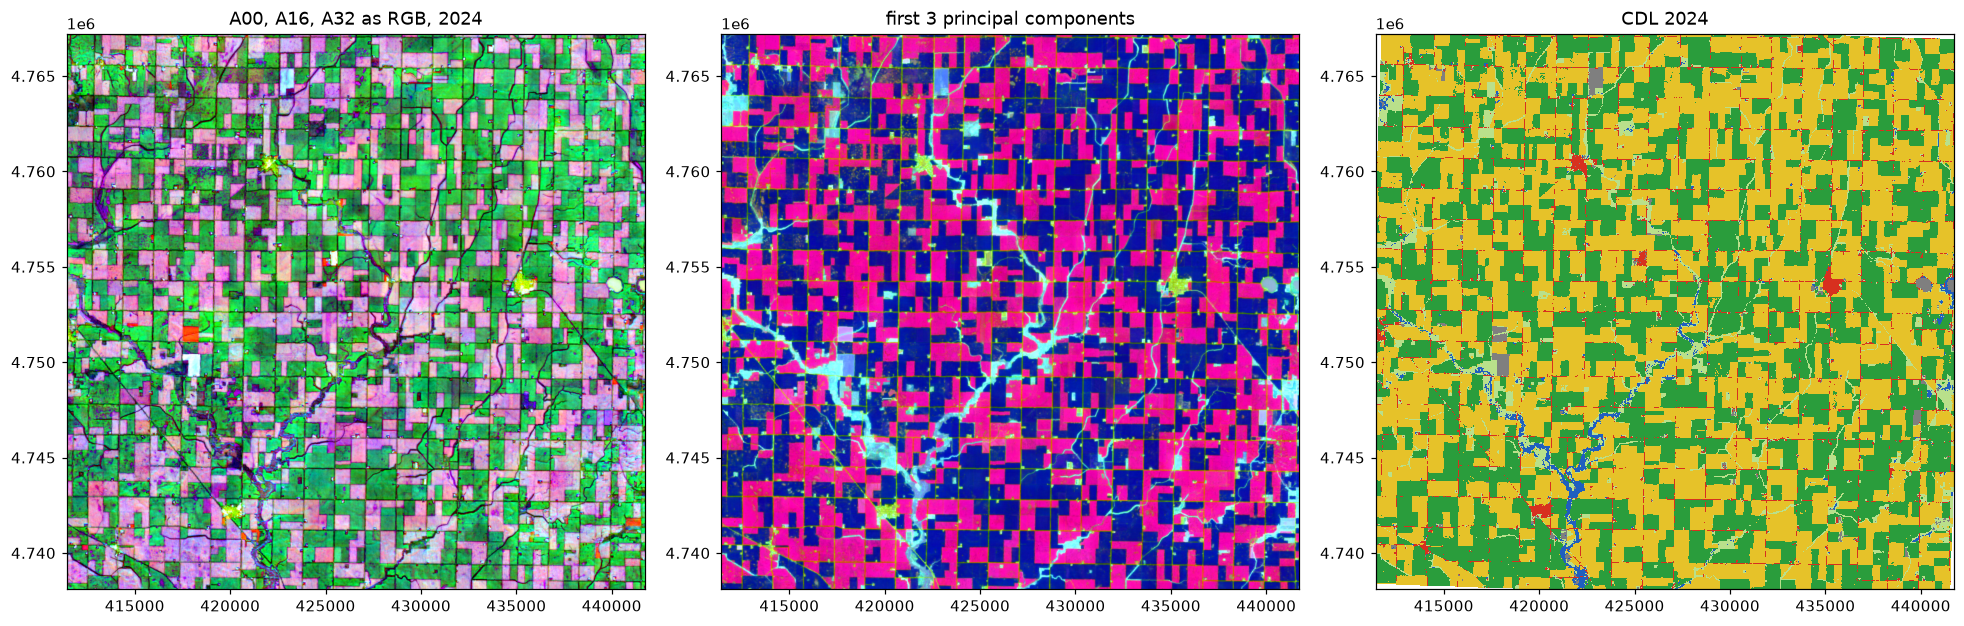

In [4]:
from matplotlib.colors import ListedColormap  # class colours
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]  # one per class
ext = [float(grid.x.min()), float(grid.x.max()), float(grid.y.min()), float(grid.y.max())]  # extent
three = ae[2024].isel(embedding=[0, 16, 32]).transpose("y", "x", "embedding").values  # A00, A16, A32
three = (three - np.nanpercentile(three, 2, (0, 1))) / (np.nanpercentile(three, 98, (0, 1)) - np.nanpercentile(three, 2, (0, 1)))  # stretch
fig, ax = plt.subplots(1, 3, figsize=(18, 5.8))  # three panels
ax[0].imshow(np.clip(np.nan_to_num(three), 0, 1), extent=ext); ax[0].set_title("A00, A16, A32 as RGB, 2024")  # raw dimensions
ax[1].imshow(fm.embedding_rgb(ae[2024]).transpose("y", "x", "band"), extent=ext); ax[1].set_title("first 3 principal components")  # PCA
ax[2].imshow(np.ma.masked_less(grid.values, 0), cmap=ListedColormap(COLORS), vmin=-0.5, vmax=5.5, extent=ext, interpolation="nearest"); ax[2].set_title("CDL 2024")  # reference
plt.tight_layout(); plt.show()  # draw

Even three raw dimensions show the field pattern, and the first three principal components of all 64
reproduce the CDL almost field for field: one colour for corn, another for soybeans, a third for the
grass and wetland strips along the streams, small dots for farmsteads and a thin grid for the roads.
Each vector summarizes a whole year of observations, so the crop of the year, not the look of one day,
is what dominates it.

## Fields like this one

One pixel in the middle of a large 2024 corn field is the query. `fm.similarity_map` computes its
cosine similarity with every pixel; thresholding the map gives "fields like this one", scored against
the CDL corn class.

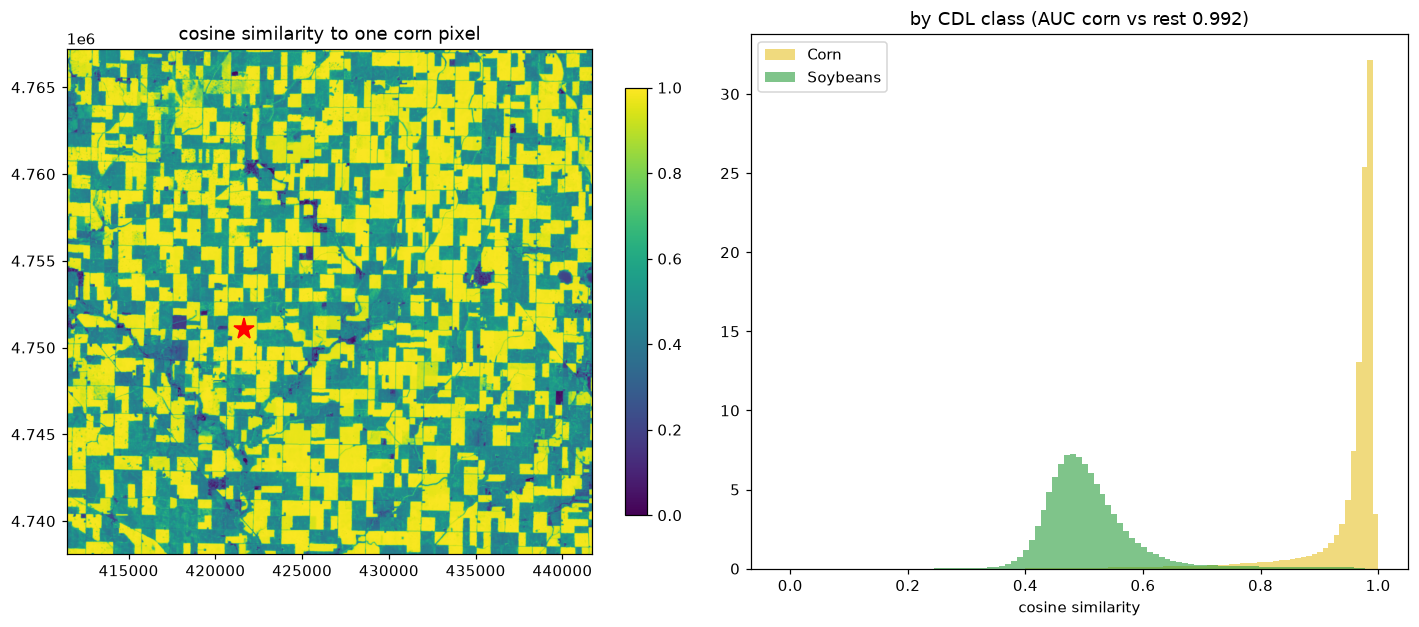

In [5]:
corn = (grid.values == 0)  # CDL corn pixels
from scipy import ndimage  # distance inside fields
depth = ndimage.distance_transform_edt(corn)  # distance to the nearest non-corn pixel
qy, qx = np.unravel_index(np.argmax(depth), depth.shape)  # the most interior corn pixel
sim = fm.similarity_map(ae[2024], ae[2024].isel(y=qy, x=qx))  # cosine similarity to it
valid = grid.values >= 0  # labelled pixels
auc = roc_auc_score(corn[valid], np.nan_to_num(sim.values[valid]))  # how well similarity ranks corn first
fig, ax = plt.subplots(1, 2, figsize=(13, 5.8))  # map and histogram
im = ax[0].imshow(sim, cmap="viridis", vmin=0, vmax=1, extent=ext); plt.colorbar(im, ax=ax[0], shrink=0.8)  # similarity map
ax[0].plot(float(grid.x[qx]), float(grid.y[qy]), "r*", ms=14); ax[0].set_title("cosine similarity to one corn pixel")  # query
for k, c in [(0, "Corn"), (1, "Soybeans")]:  # two crops
    ax[1].hist(sim.values[grid.values == k], 100, alpha=0.6, label=c, color=COLORS[k], density=True)  # distributions
ax[1].legend(); ax[1].set_xlabel("cosine similarity"); ax[1].set_title(f"by CDL class (AUC corn vs rest {auc:.3f})")  # labels
plt.tight_layout(); plt.show()  # draw

One pixel is enough. Corn pixels have cosine similarities near 1 to the query, soybean pixels mostly
between 0.4 and 0.6, and the similarity ranks corn above everything else with an AUC of about 0.99. A
threshold anywhere between 0.75 and 0.85 would give a corn map with no training beyond the single
query. This works because a year of observations separates crops with different calendars so well;
classes that look alike all year, such as different grass covers, would not separate like this.

## Clusters without labels

K-means with six clusters on a random sample of pixels, applied to the whole map, compared with the six
CDL groups by the adjusted Rand index (ARI).

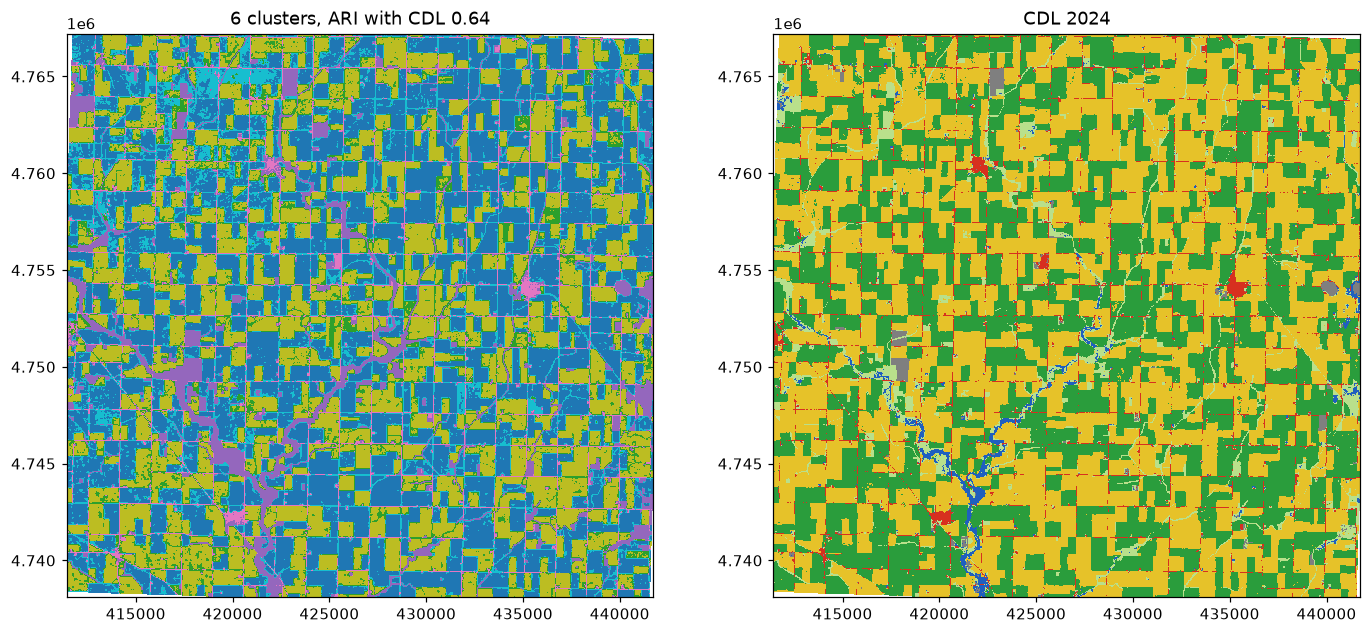

col_0,0,1,2,3,4,5
row_0,,,,,,
Corn,1.0,0.08,0.07,0.20,0.0,0.83
Developed,0.0,0.04,0.07,0.45,0.0,0.05
Grass/pasture,0.0,0.03,0.58,0.06,0.0,0.04
Other,0.0,0.00,0.09,0.02,0.0,0.00
Soybeans,0.0,0.84,0.05,0.26,1.0,0.07
Wetland/forest,0.0,0.00,0.14,0.00,0.0,0.01


In [6]:
from sklearn.cluster import KMeans  # clustering

X = ae[2024].values.reshape(64, -1).T  # (pixels, 64)
okp = np.isfinite(X).all(1) & (grid.values.ravel() >= 0)  # labelled pixels with embeddings
rng = np.random.default_rng(SEED); samp = rng.choice(np.flatnonzero(okp), 50000, replace=False)  # 50,000 for fitting
km = KMeans(6, n_init=10, random_state=SEED).fit(X[samp])  # six clusters
lab = np.full(X.shape[0], -1); lab[okp] = km.predict(X[okp])  # every labelled pixel
ari = adjusted_rand_score(grid.values.ravel()[okp], lab[okp])  # agreement with the CDL
ct = pd.crosstab(pd.Series(grid.values.ravel()[okp]).map(dict(enumerate(CLASSES))), lab[okp], normalize="columns").round(2)  # cluster composition
fig, ax = plt.subplots(1, 2, figsize=(13, 5.8))  # clusters and CDL
ax[0].imshow(np.ma.masked_less(lab.reshape(grid.shape), 0), cmap="tab10", interpolation="nearest", extent=ext); ax[0].set_title(f"6 clusters, ARI with CDL {ari:.2f}")  # clusters
ax[1].imshow(np.ma.masked_less(grid.values, 0), cmap=ListedColormap(COLORS), vmin=-0.5, vmax=5.5, extent=ext, interpolation="nearest"); ax[1].set_title("CDL 2024")  # reference
plt.tight_layout(); plt.show()  # draw
ct  # share of each CDL class in each cluster

Without any labels, k-means finds clusters that are almost pure crop classes: two of corn (one of
them 100 % corn), two of soybeans, one dominated by grass and pasture and one by developed land, which
is mostly the road grid. The adjusted Rand index with the CDL is about 0.64; it is lower than the purity
suggests because corn and soybeans are each split across two clusters (for example fields with
different planting dates) and the small classes mix.

## Change between 2020 and 2024

`fm.embedding_change` is 1 minus the cosine similarity of the two years at each pixel. In the Corn
Belt most change is crop rotation: a corn field in 2020 is often soybeans in 2024 and the reverse.
The change map is compared with the CDL: did the crop group of the pixel change between the years?

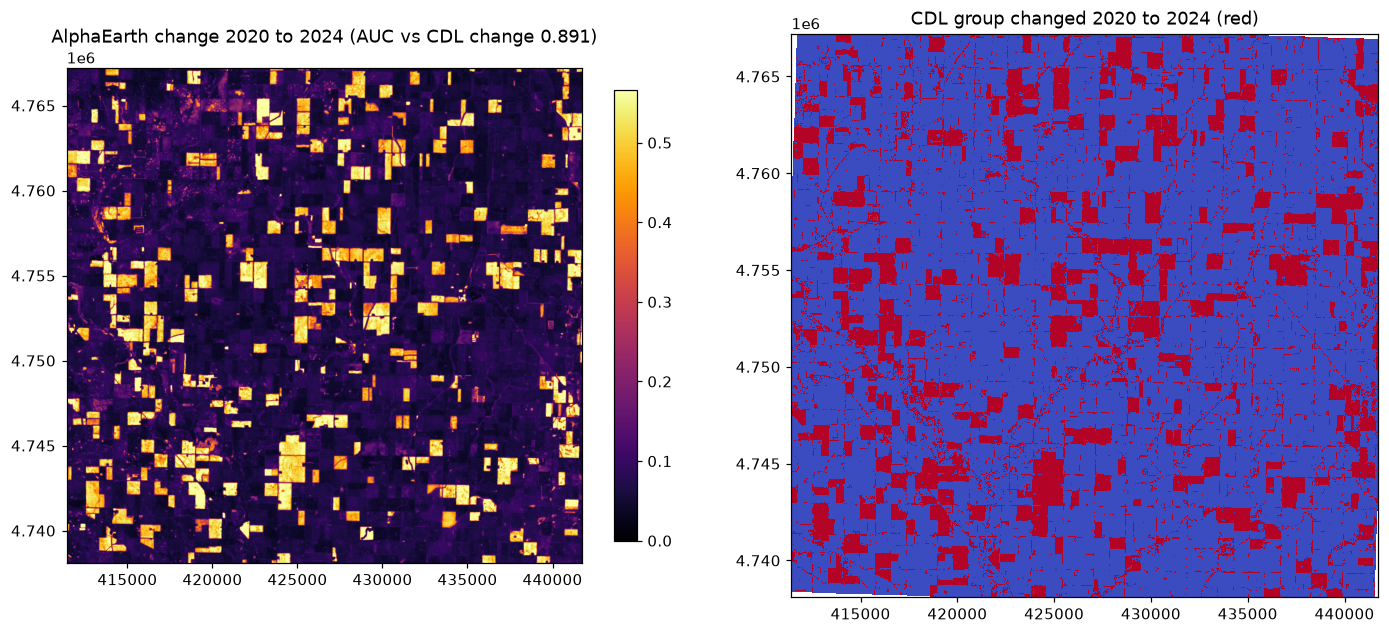

,median change
Corn -> Corn,0.073
Corn -> Soybeans,0.494
Soybeans -> Corn,0.483
Soybeans -> Soybeans,0.056


In [7]:
chg = fm.embedding_change(ae[2020], ae[2024])  # 1 - cosine, per pixel
c20, c24 = cdl_all.sel(year=2020).values, cdl_all.sel(year=2024).values  # CDL of both years
both = (c20 >= 0) & (c24 >= 0) & np.isfinite(chg.values)  # labelled in both years
rotated = (c20 != c24)  # crop group changed
auc_c = roc_auc_score(rotated[both], chg.values[both])  # change map vs CDL change
fig, ax = plt.subplots(1, 2, figsize=(13, 5.8))  # change and CDL change
im = ax[0].imshow(chg, cmap="inferno", vmin=0, vmax=float(np.nanpercentile(chg, 98)), extent=ext); plt.colorbar(im, ax=ax[0], shrink=0.8)  # change
ax[0].set_title(f"AlphaEarth change 2020 to 2024 (AUC vs CDL change {auc_c:.3f})")  # title
ax[1].imshow(np.where(both, rotated, np.nan), cmap="coolwarm", extent=ext, interpolation="nearest"); ax[1].set_title("CDL group changed 2020 to 2024 (red)")  # reference
plt.tight_layout(); plt.show()  # draw
pd.DataFrame({"median change": {f"{a} -> {b}": float(np.median(chg.values[both & (c20 == i) & (c24 == j)]))
              for i, a in enumerate(CLASSES[:2]) for j, b in enumerate(CLASSES[:2])}}).round(3)  # by transition

The change map is almost a binary map of crop rotation: fields that switched between corn and
soybeans have a change near 0.5, fields that kept their crop near 0.06 to 0.07. It ranks pixels whose
CDL group changed above those that did not with an AUC of about 0.89; the misses are mostly field edges
and the thin road and stream lines, where the 20 m CDL and the embeddings disagree on a pixel or two.
The annual embeddings make crop rotation history available for every field without classifying any
year.

## AlphaEarth, DOFA and SSL4EO on the same probe

The 640 m cell probe of notebooks 09_11_03 and 09_11_04, for 2024: corn or soybean cells, folds over
5.8 km blocks. AlphaEarth pixels are averaged per cell; DOFA and SSL4EO patch features come from the
31 August 2024 Sentinel-2 scene, averaged per cell as in notebook 09_11_04.

In [8]:
CELL = 32; NY, NX = -(-grid.shape[0] // CELL), -(-grid.shape[1] // CELL)  # 640 m cells
pad = np.full((NY * CELL, NX * CELL), -1); pad[:grid.shape[0], :grid.shape[1]] = grid.values  # padded CDL
blk = pad.reshape(NY, CELL, NX, CELL).transpose(0, 2, 1, 3).reshape(NY * NX, -1)  # pixels per cell
cnt = np.stack([(blk == k).sum(1) for k in (0, 1)], 1); y_c, pur = cnt.argmax(1), cnt.max(1) / blk.shape[1]  # labels
gy, gx = np.divmod(np.arange(NY * NX), NX); group = (gy // 9) * 10 + gx // 9; ok = pur >= 0.6  # blocks, usable


def cells(d):  # (D, y, x) -> (cells, D) on the 640 m grid
    f = int(round(d.sizes["y"] / NY))  # pixels or patches per cell side
    d = d.coarsen(y=f, x=f, boundary="pad").mean() if f > 1 else d  # average
    return np.nan_to_num(d.values[:, :NY, :NX].reshape(d.sizes[d.dims[0]], -1).T)  # (cells, D)


s2 = xr.open_dataarray(CUBE / "s2_20m.nc").sel(time="2024-08-31").drop_vars("time").load().rio.write_crs("EPSG:32615")  # Sentinel-2
F = {"band means (baseline)": cells(s2), "AlphaEarth (64)": cells(ae[2024])}  # baseline and AlphaEarth
for n in ["dofa-base", "ssl4eo-s12-vits16-dino"]:  # two encoders
    e = fm.load_model(n, device=DEVICE); F[n] = cells(e.embed_raster(s2, dense=True, norm="model", batch_size=8))  # patch features
    del e; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
bench = fm.benchmark_encoders({k: {"embeddings": v[ok]} for k, v in F.items()}, y_c[ok], groups=group[ok], cv=5)  # same folds
bench[["embed_dim", "linear_f1_macro", "knn_accuracy"]].round(3)

,embed_dim,linear_f1_macro,knn_accuracy
input,,,
band means (baseline),10,0.990,0.960
AlphaEarth (64),64,1.000,1.000
dofa-base,768,0.934,0.767
ssl4eo-s12-vits16-dino,384,0.988,0.974


AlphaEarth's 64 values per cell classify the 2024 corn and soybean cells perfectly (macro F1 1.0, kNN
accuracy 1.0). The band means of a single late-August Sentinel-2 date are already almost as good
(0.99), and the SSL4EO ViT patch features match them; DOFA's patch features trail (0.93). AlphaEarth
wins because it sees the whole year from several sensors, while the other inputs see one date, and it
costs nothing to compute here. Its price is the opposite limitation: it can never show what happened
on one particular day.

## Embeddings at soil sampling points

`fm.sample_alphaearth` returns the 64 values at each point, with the point's other columns kept; it reads
one small chunk of the Zarr mosaic per point, sixteen at a time. The 570 Great Plains topsoil samples are
sampled for 2020 and cached for notebook 09_11_08.

In [9]:
soil = gpd.read_file(GP)  # 570 SOC samples (Albers)
path = OUT / "gp_soc_alphaearth_2020.csv"  # cache for notebook 09_11_08
if not path.exists():  # sample once
    t0 = time.perf_counter()  # start the clock
    tab = fm.sample_alphaearth(soil, 2020)  # 64 columns per point, read from the Zarr mosaic
    tab.assign(x=soil.geometry.x, y=soil.geometry.y).drop(columns="geometry").to_csv(path, index=False)  # cache
    print(f"sampled in {time.perf_counter() - t0:.0f} s")  # timing
tab = pd.read_csv(path)  # the cached table
print(tab.shape, "| points without embeddings:", int(tab[fm.ALPHAEARTH_BANDS].isna().any(axis=1).sum()))  # summary
tab[["SiteID", "SOC"] + fm.ALPHAEARTH_BANDS[:5]].head()

(570, 68) | points without embeddings: 0


,SiteID,SOC,A00,A01,A02,A03,A04
0,1,2.304,0.041584,0.015748,0.119093,-0.015748,0.027128
1,2,3.154,0.135886,-0.059116,0.093564,-0.008858,0.084214
2,3,1.309,0.024606,-0.206936,0.079723,0.032541,0.147697
3,4,4.717,-0.008858,-0.113741,0.006151,-0.001538,0.135886
4,5,2.230,0.041584,-0.147697,0.051734,0.035433,0.153787


## Summary and exercises

### Summary

- AlphaEarth Foundations publishes a 64-value, unit-length embedding per 10 m pixel and year since
  2017, in Earth Engine and as public Zarr and GeoTIFF copies that need no account;
  `fm.alphaearth_to_xarray` and `fm.sample_alphaearth` read them into GeoLattice.
- Dot products are cosine similarities, so "fields like this one", clustering and change detection
  need only array arithmetic.
- Without any model to run, AlphaEarth separates crops and land cover as well as or better than
  embeddings computed from a single Sentinel-2 date, because each vector summarizes a year of many sensors.
- Change between years in the Corn Belt is dominated by crop rotation, which the change map follows.
- The annual summary cannot map within-season events; its dimensions have no physical names.

### Exercises

1. Repeat the similarity search with a query in a soybean field and with one in a town.
2. Cluster with 10 clusters and name each from its CDL composition table.
3. Compute the change between consecutive years 2020 to 2024 and find pixels that changed every year.
4. Read 2017 and 2024 at 100 m for all of Iowa (`scale=100`, which uses the GeoTIFF overviews) and map
   the largest changes.
5. Train a random forest on AlphaEarth to predict the 2024 CDL and apply it to 2025 embeddings. How
   well does a classifier trained on one year transfer to the next?

### References

- Brown, C. F. et al. (2025). AlphaEarth Foundations: an embedding field model for accurate and efficient global mapping from sparse label data. arXiv:2507.22291.
- Google Earth Engine Data Catalog. Satellite Embedding V1, GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL.
- Gorelick, N. et al. (2017). Google Earth Engine: planetary-scale geospatial analysis for everyone. Remote Sensing of Environment.